### Travel Planner Agent

#### Motivation
In the realm of AI applications, managing state and flow in multi-step processes can be challenging. LangGraph provides a solution by allowing developers to create graph-based workflows that can handle complex interactions while maintaining a clear and modular structure. This Travel Planner serves as a practical example of how to leverage LangGraph's capabilities to build a useful and interactive application.

Key Components

StateGraph: The core of our application, defining the flow of our Travel Planner.

PlannerState: A custom type representing the state of our planning process.

Node Functions: Individual steps in our planning process (input_city, input_interests, create_itinerary).

LLM Integration: Utilizing a language model to generate the final itinerary.

In [ ]:
import os
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.runnables.graph import MermaidDrawMethod
from IPython.display import display, Image

os.environ["GROQ_API_KEY"] = "xxxxxxxxxxxxxx"

In [2]:
# Defining state(for current/updated status)
class TravelState(TypedDict):
    user_request: str
    travel_details: str
    itinerary: str
    budget: str
    final_plan: str

In [3]:
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.7)

### NODE
Input:  the full state (dict)

Output: a partial dict of keys to update

In [4]:
#Nodes

def gather_info(state: TravelState) -> dict:
    r = llm.invoke([
        SystemMessage(content="Extract destination, duration, travelers, budget style, interests from the request. Be concise."),
        HumanMessage(content=state["user_request"])
    ])
    return {"travel_details": r.content}

def plan_itinerary(state: TravelState) -> dict:
    r = llm.invoke([
        SystemMessage(content="Create a short day-by-day itinerary. Morning/afternoon/evening. 2-3 lines per day."),
        HumanMessage(content=f"Request: {state['user_request']}\nDetails: {state['travel_details']}")
    ])
    return {"itinerary": r.content}

def budget_estimate(state: TravelState) -> dict:
    r = llm.invoke([
        SystemMessage(content="Give a rough budget breakdown in INR: accommodation, food, transport, activities, total."),
        HumanMessage(content=f"Details: {state['travel_details']}\nItinerary: {state['itinerary']}")
    ])
    return {"budget": r.content}

def final_summary(state: TravelState) -> dict:
    r = llm.invoke([
        SystemMessage(content="Combine everything into a clean, exciting final travel plan with emojis and sections."),
        HumanMessage(content=f"Details:\n{state['travel_details']}\n\nItinerary:\n{state['itinerary']}\n\nBudget:\n{state['budget']}")
    ])
    return {"final_plan": r.content}



In [5]:
graph = StateGraph(TravelState)

graph.add_node("gather_info", gather_info)
graph.add_node("plan_itinerary", plan_itinerary)
graph.add_node("budget_estimate", budget_estimate)
graph.add_node("final_summary", final_summary)

graph.add_edge(START, "gather_info")
graph.add_edge("gather_info", "plan_itinerary")
graph.add_edge("plan_itinerary", "budget_estimate")
graph.add_edge("budget_estimate", "final_summary")
graph.add_edge("final_summary", END)

app = graph.compile()

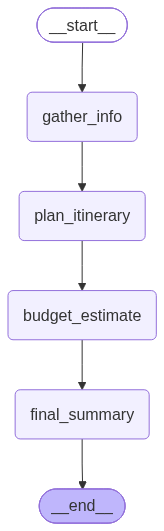

In [15]:
display(
    Image(
        app.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)

In [10]:
result = app.invoke({
    "user_request": "3 days in Jibhi, 2 people, low-range, love bike ride and food",
    "travel_details": "",
    "itinerary": "",
    "budget": "",
    "final_plan": ""
})

print(result["final_plan"])

## 🌄 Jibhi — 3‑Day Low‑Budget Adventure  
**Travelers:** 2 people **Duration:** 3 days **Style:** Backpack‑friendly, bike‑centric, food‑loving  
**Base cost:** **≈ ₹5,500 – ₹8,500** (≈ $65 – $100)  

---

### 📋 QUICK OVERVIEW
| 📅 Day | 🚲 Main Ride | 🍽️ Food Highlights | 🏠 Stay |
|-------|--------------|--------------------|--------|
| **1** | Gentle loop Jibhi‑Rohru road | Dal‑chana + butter naan @ The Bamboo House | Budget homestay (₹800‑₹1,200) |
| **2** | Off‑road to Chalunki waterfall (6 km) | Kullu rajma @ Mohan’s Kitchen + picnic | Same homestay (community dinner) |
| **3** | Ridge road to Kunal Bhatta (12 km) | Aloo‑paratha @ Shivam’s Dhaba + chai‑pakora | Pack & depart |

---

## 🗓️ DETAILED DAY‑BY‑DAY PLAN  

### **Day 1 – Arrival & Easy Exploration**  
| ⏰ Time | ✅ What to Do | 🍴 Food | 💰 Cost (₹) |
|--------|--------------|--------|------------|
| **Morning** | • Arrive via shared taxi / local bus <br>• Check‑in to a homestay (₹800‑₹1,200) <br>• Rent a mountain bike from **J